In [11]:
Landuse_map = 'Mapbiomas'

In [3]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *

"""
1. Load your evaporation dataset here
"""
print('To run the model, your data format should be:')
print('Latitude = [ 90 → -90 ]')
print('Longitude = [ 0 → 360 ]')
print(' ')

lats=np.arange(90,-90,-0.5)
lons=np.arange(0,360,0.5)

Evap_agg = xr.open_mfdataset('/home/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

print('Your Evaporation data:')
print('Latitude = [', Evap_agg.lat[0].values, '→', Evap_agg.lat[-1].values, ']')
print('Longitude = [', Evap_agg.lon[0].values, '→', Evap_agg.lon[-1].values, ']')


"""
2. Funtion for forwardtracking (monthly) [Annual can be derived using 'np.sum' funtion] 
"""
### Forward tracking
def get_closest_index(lats,lat):
    import operator
    lat_index, min_value = min(enumerate(abs(lats-lat)), key=operator.itemgetter(1))
    return lat_index

    
def MR_footprint_forward(month, latitude, longitude):
    latidx=get_closest_index(lats,latitude)
    lonidx=get_closest_index(lons,longitude)
    
    MR = xr.open_dataset('/home/chandra/data/Paper4_Self-influencing_feedback/utrack_climatology/utrack_climatology_0.5_'+
                                                         str(month).zfill(2)+'.nc').moisture_flow
    fp = MR[get_closest_index(lats,latitude), get_closest_index(lons,longitude),:,:].values
    fp=fp*-0.1
    fp=np.e**fp
    fp[fp==1]=0
    forward_fp=fp/np.nansum(fp)
    #print(np.nansum(forward_fp).round(2))
    forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), 
                                                 get_closest_index(lons,longitude)].values)
    return forward_fp


def absolute_forward_tracking(j):
    Evap_footprint_monthly = np.zeros(shape=(12,360,720))
    Evap_footprint_monthly_final  = np.zeros(shape=(12,360,720))
    #for j in tqdm(range(Screened_data.shape[0])):
    latitude, longitude = np.array(Screened_data.loc[j])
    #print(latitude, longitude, '\n')
    for i in tqdm(range(12)):
        Evap_footprint_monthly[i,:,:] = MR_footprint_forward(i+1,latitude,longitude)
    Evap_footprint_monthly_final = Evap_footprint_monthly_final + Evap_footprint_monthly

    #Evap_footprint_monthly_sum = xr.DataArray(Evap_footprint_monthly_final, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
    #             dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
    return Evap_footprint_monthly_final




/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


To run the model, your data format should be:
Latitude = [ 90 → -90 ]
Longitude = [ 0 → 360 ]
 
Your Evaporation data:
Latitude = [ 89.75 → -89.75 ]
Longitude = [ 0.0 → 359.5 ]


/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/plugins.py:64: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [ ]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360
data

In [5]:
Lat = []
for lat in np.argwhere(data.values == 1).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 1).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholders_'+Landuse_map+'.nc')


  0%|          | 0/12 [00:00<?, ?it/s]6.67s/it]

100%|██████████| 12/12 [01:21<00:00,  6.80s/it]

100%|██████████| 12/12 [01:21<00:00,  6.82s/it]

100%|██████████| 12/12 [01:22<00:00,  6.91s/it]

100%|██████████| 12/12 [01:23<00:00,  6.94s/it]

100%|██████████| 12/12 [01:23<00:00,  6.99s/it]

100%|██████████| 12/12 [00:50<00:00,  4.24s/it]

100%|██████████| 12/12 [00:57<00:00,  4.77s/it]

100%|██████████| 12/12 [00:54<00:00,  4.64s/it]

100%|██████████| 12/12 [00:56<00:00,  4.72s/it]



100%|██████████| 12/12 [00:54<00:00,  4.56s/it]

100%|██████████| 12/12 [00:52<00:00,  4.39s/it]

100%|██████████| 12/12 [00:53<00:00,  4.49s/it]

100%|██████████| 12/12 [00:51<00:00,  4.29s/it]

100%|██████████| 12/12 [00:54<00:00,  4.53s/it]

100%|██████████| 12/12 [00:51<00:00,  4.32s/it]

100%|██████████| 12/12 [00:53<00:00,  4.44s/it]

100%|██████████| 12/12 [00:51<00:00,  4.30s/it]

100%|██████████| 12/12 [01:00<00:00,  5.07s/it]

100%|██████████| 12/12 [00:50<00:00,  4.21s/it]

  0%|          | 0

In [12]:
Lat = []
for lat in np.argwhere(data.values == 2).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 2).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Mediumholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [00:59<00:00,  4.98s/it]

100%|██████████| 12/12 [01:00<00:00,  5.00s/it]

100%|██████████| 12/12 [01:00<00:00,  5.02s/it]

100%|██████████| 12/12 [01:02<00:00,  5.18s/it]

100%|██████████| 12/12 [01:02<00:00,  5.24s/it]

100%|██████████| 12/12 [01:03<00:00,  5.27s/it]

100%|██████████| 12/12 [01:03<00:00,  5.31s/it]

100%|██████████| 12/12 [01:03<00:00,  5.31s/it]

100%|██████████| 12/12 [01:05<00:00,  5.44s/it]

100%|██████████| 12/12 [00:49<00:00,  4.16s/it]

  0%|          | 0/12 [00:00<?, ?it/s]

100%|██████████| 12/12 [01:15<00:00,  6.32s/it]

100%|██████████| 12/12 [00:52<00:00,  4.34s/it]

  8%|▊         | 1/12 [00:04<00:49,  4.49s/it]]

100%|██████████| 12/12 [00:38<00:00,  3.17s/it]

100%|██████████| 12/12 [00:35<00:00,  2.99s/it]


In [4]:
Lat = []
for lat in np.argwhere(data.values == 3).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 3).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)
Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Largeholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [01:05<00:00,  5.50s/it]

100%|██████████| 12/12 [01:06<00:00,  5.50s/it]

100%|██████████| 12/12 [01:06<00:00,  5.55s/it]

100%|██████████| 12/12 [01:06<00:00,  5.18s/it]

100%|██████████| 12/12 [01:06<00:00,  5.58s/it]

100%|██████████| 12/12 [01:06<00:00,  5.58s/it]

100%|██████████| 12/12 [01:08<00:00,  5.68s/it]

  0%|          | 0/12 [00:00<?, ?it/s]5.72s/it]

100%|██████████| 12/12 [01:10<00:00,  5.86s/it]

100%|██████████| 12/12 [00:53<00:00,  4.43s/it]

100%|██████████| 12/12 [00:52<00:00,  4.37s/it]

100%|██████████| 12/12 [00:52<00:00,  4.33s/it]

  0%|          | 0/12 [00:00<?, ?it/s]4.67s/it]

100%|██████████| 12/12 [00:56<00:00,  4.69s/it]


100%|██████████| 12/12 [00:55<00:00,  4.60s/it]

100%|██████████| 12/12 [00:52<00:00,  4.38s/it]

100%|██████████| 12/12 [00:51<00:00,  4.32s/it]

100%|██████████| 12/12 [00:52<00:00,  4.39s/it]

100%|██████████| 12/12 [00:53<00:00,  4.44s/it]

100%|██████████| 12/12 [00:54<00:00,  4.57s/it]

100%|██████████| 12

In [ ]:
Lat = []
for lat in np.argwhere(data.values < 4).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values < 4).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool(processes=10)
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)
"""
for i in tqdm(range(Screened_data.shape[0])):
    if i == 0:
        a = absolute_forward_tracking(i)
    else:
        b = absolute_forward_tracking(i)
        a = np.nansum([a,b], axis = 0)
        np.save('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_All_stakeholders_'+Landuse_map+'.nc', a)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_All_stakeholders_'+Landuse_map+'.nc')


Text(0.5, 1.0, 'Forwardtracking: mm/year')

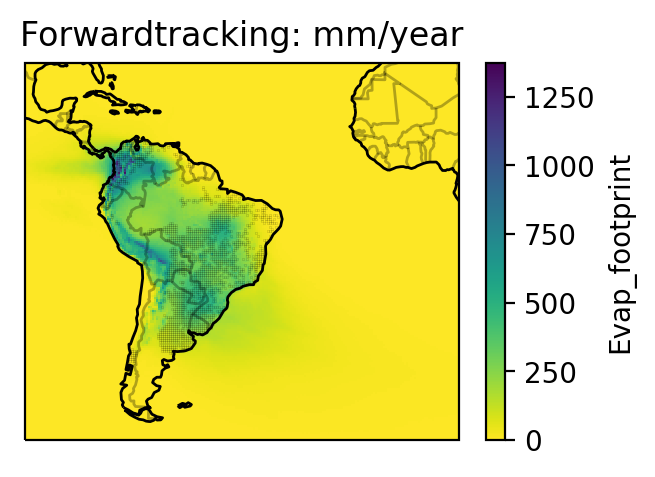

In [25]:
fig = plt.figure(figsize=(3.5, 2.5), dpi = 200)
ax = [plt.subplot(111,projection=ccrs.PlateCarree(), aspect='auto')]
Evap_footprint_monthly_sum.sum(dim = 'month').plot(ax = ax[0], vmin = 0, cmap = 'viridis_r',)
ax[0].coastlines(lw = 1)
ax[0].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=.3)
ax[0].set_xlim(-100,10)
ax[0].set_ylim(-60, 30)
ax[0].scatter(np.array(Screened_data['Lon']), np.array(Screened_data['Lat']), c='black', alpha = 0.7, s = 0.01, marker = '.')
ax[0].set_title('Forwardtracking: mm/year')

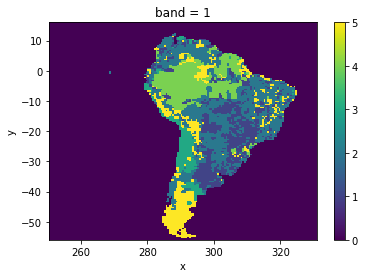

In [6]:
Lat = []
for lat in np.argwhere(data[0].values > 0).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values > 0).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Actor_dominance_HilDA+/Forwardtracking_Largeholders.nc')

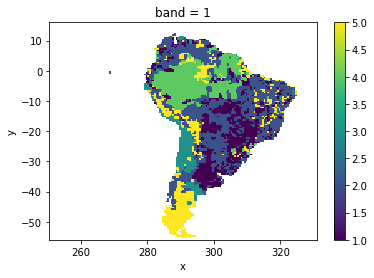

In [13]:
data.where((data.values >= 1) & (data.values <= 5)).plot()

In [ ]:
## For stakeolder forest only

In [4]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360
data = data[:,:-1]
#data

LU_Mapbiomas_forest = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif')[0,::-1]
LU_Mapbiomas_forest['x'] = LU_Mapbiomas_forest.x.values%360
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sortby('x')
#LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sel(y = slice(-39.25, 10.25), x = slice(280, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.where(LU_Mapbiomas_forest != 0)
LU_Mapbiomas_forest = LU_Mapbiomas_forest[::-1,]

/tmp/ipykernel_44349/516397358.py:10: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  LU_Mapbiomas_forest = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif')[0,::-1]


In [19]:
data_f = data.where((data == 1) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f
Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [21]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:51<00:00, 14.26s/it]

100%|██████████| 12/12 [01:54<00:00,  9.52s/it]

100%|██████████| 12/12 [01:51<00:00,  9.26s/it]

100%|██████████| 12/12 [01:54<00:00,  9.54s/it]

100%|██████████| 12/12 [02:24<00:00, 12.07s/it]

100%|██████████| 12/12 [01:56<00:00,  9.71s/it]

100%|██████████| 12/12 [01:17<00:00,  6.48s/it]


In [26]:
data_f = data.where((data == 2) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f
Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [27]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Mediumholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:03<00:00, 10.25s/it]

100%|██████████| 12/12 [02:03<00:00, 10.30s/it]

100%|██████████| 12/12 [00:59<00:00,  4.95s/it]


In [28]:
data_f = data.where((data == 3) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f
Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [29]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_forward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Largeholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:01<00:00, 10.14s/it]

100%|██████████| 12/12 [01:56<00:00,  9.74s/it]

100%|██████████| 12/12 [01:38<00:00,  8.17s/it]

100%|██████████| 12/12 [02:03<00:00, 10.27s/it]

100%|██████████| 12/12 [02:02<00:00, 10.21s/it]

100%|██████████| 12/12 [02:00<00:00, 10.04s/it]

100%|██████████| 12/12 [01:57<00:00,  9.76s/it]

100%|██████████| 12/12 [02:01<00:00, 10.13s/it]

100%|██████████| 12/12 [01:43<00:00,  8.64s/it]

100%|██████████| 12/12 [01:21<00:00,  6.81s/it]


In [2]:
### Local moisture recycling

In [ ]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *

Landuse_map = 'Mapbiomas'

"""
1. Load your evaporation dataset here
"""
print('To run the model, your data format should be:')
print('Latitude = [ 90 → -90 ]')
print('Longitude = [ 0 → 360 ]')
print(' ')

lats=np.arange(90,-90,-0.5)
lons=np.arange(0,360,0.5)

Evap_agg = xr.open_mfdataset('/home/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

print('Your Evaporation data:')
print('Latitude = [', Evap_agg.lat[0].values, '→', Evap_agg.lat[-1].values, ']')
print('Longitude = [', Evap_agg.lon[0].values, '→', Evap_agg.lon[-1].values, ']')


"""
2. Funtion for forwardtracking (monthly) [Annual can be derived using 'np.sum' funtion] 
"""
### Forward tracking
def get_closest_index(lats,lat):
    import operator
    lat_index, min_value = min(enumerate(abs(lats-lat)), key=operator.itemgetter(1))
    return lat_index

    
def MR_footprint_forward_recycling(latitude, longitude, neigbouringpixel = 0):
    global forward_fp, Evap_agg_recycled
    latidx=get_closest_index(lats,latitude)
    lonidx=get_closest_index(lons,longitude)
    
    Evap_agg_recycled = []
    for month in range(1,13):
        MR = xr.open_dataset('/home/chandra/data/Paper4_Self-influencing_feedback/utrack_climatology/utrack_climatology_0.5_'+
                                                                 str(month).zfill(2)+'.nc').moisture_flow
        fp = MR[get_closest_index(lats,latitude), get_closest_index(lons,longitude), :, :].values
        fp=fp*-0.1
        fp=np.e**fp
        fp[fp==1]=0
        forward_fp=fp/np.nansum(fp)
        if int(neigbouringpixel) == 1:
            print('calculating 3x3')
            forward_fp= forward_fp[get_closest_index(lats,latitude)-1:get_closest_index(lats,latitude)+2, get_closest_index(lons,longitude)-1:get_closest_index(lons,longitude)+2]
            forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), get_closest_index(lons,longitude)].values)
            Evap_agg_recycled.append(forward_fp)
            continue
        if int(neigbouringpixel) == 2:
            print('calculating 5x5')
            forward_fp= forward_fp[get_closest_index(lats,latitude)-2:get_closest_index(lats,latitude)+3, get_closest_index(lons,longitude)-2:get_closest_index(lons,longitude)+3]
            forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), get_closest_index(lons,longitude)].values)
            Evap_agg_recycled.append(forward_fp)
            continue
        else:
            print('calculating 1x1')
            forward_fp = forward_fp[get_closest_index(lats,latitude), get_closest_index(lons,longitude)]
            forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), get_closest_index(lons,longitude)].values)
            Evap_agg_recycled.append(forward_fp)
            continue
    Evap_agg_recycled = np.nansum(Evap_agg_recycled, axis = 0)
    print(Evap_agg_recycled)
    return Evap_agg_recycled


"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360

Lat = []
for lat in np.argwhere(data.values > 0).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values > 0).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})


Evap_footprint = np.zeros(shape=(360,720))
Evap_footprint[:] = np.nan

#for i in tqdm(range(Screened_data.shape[0])):
var_start = input("Start the loop value: ")
var_start = int(var_start)
var_stop = var_start+10
neigbouringpixel = input("Neigbouring pixel: ")
if var_stop > Screened_data.shape[0]:
    var_stop = Screened_data.shape[0]
print("You entered: " + str(var_start), str(var_stop))
for i in tqdm(range(var_start,var_stop)):
    latitude, longitude = (Screened_data.iloc[i]).values
    if int(neigbouringpixel) == 1:
        Original_array = Evap_footprint[get_closest_index(lats,latitude)-1:get_closest_index(lats,latitude)+2, get_closest_index(lons,longitude)-1:get_closest_index(lons,longitude)+2]
        Evap_footprint[get_closest_index(lats,latitude)-1:get_closest_index(lats,latitude)+2, 
                       get_closest_index(lons,longitude)-1:get_closest_index(lons,longitude)+2] = np.nansum([Original_array, MR_footprint_forward_recycling(latitude, longitude, neigbouringpixel)], axis = 0)
        continue
    if int(neigbouringpixel) == 2:
        Original_array = Evap_footprint[get_closest_index(lats,latitude)-2:get_closest_index(lats,latitude)+3, get_closest_index(lons,longitude)-2:get_closest_index(lons,longitude)+3]
        Evap_footprint[get_closest_index(lats,latitude)-2:get_closest_index(lats,latitude)+3, 
                       get_closest_index(lons,longitude)-2:get_closest_index(lons,longitude)+3] = np.nansum([Original_array, MR_footprint_forward_recycling(latitude, longitude, neigbouringpixel)], axis = 0)
        continue
    else:
        Evap_footprint[get_closest_index(lats,latitude), get_closest_index(lons,longitude)] = MR_footprint_forward_recycling(latitude, longitude, neigbouringpixel)

Evap_footprint_monthly_sum = xr.DataArray(Evap_footprint, coords=[Evap_agg.lat.values, Evap_agg.lon.values],
                                          dims=['lat', 'lon'], name = 'Evap_footprint', 
                                          attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_recycling_'+str(var_start)+'-'+str(var_stop)+'_'+'NeighbouringPixel'+neigbouringpixel+'_.nc')

In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd

In [2]:
import glob
import pandas as pd
 
# specifying the path to csv files
path = "/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Moisture_recycling_runs/"
# Get CSV files list from a folder
nc_files = glob.glob(path + "Forwardtracking_recycling*NeighbouringPixel0_.nc")

i = 0
for files in nc_files:
    a= xr.open_dataset(files).Evap_footprint.values
    if i == 0:
        b = a
    else:
        b = np.nansum([b,a], axis = 0)
    i += 1

In [3]:
import glob
import pandas as pd
 
# specifying the path to csv files
path = "/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Moisture_recycling_runs/"
# Get CSV files list from a folder
nc_files = glob.glob(path + "Forwardtracking_recycling*NeighbouringPixel1_.nc")

i = 0
for files in nc_files:
    a= xr.open_dataset(files).Evap_footprint.values
    if i == 0:
        b_1 = a
    else:
        b_1 = np.nansum([b_1,a], axis = 0)
    i += 1

In [4]:
import glob
import pandas as pd
 
# specifying the path to csv files
path = "/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Moisture_recycling_runs/"
# Get CSV files list from a folder
nc_files = glob.glob(path + "Forwardtracking_recycling*NeighbouringPixel2_.nc")

i = 0
for files in nc_files:
    a= xr.open_dataset(files).Evap_footprint.values
    if i == 0:
        b_2 = a
    else:
        b_2 = np.nansum([b_2,a], axis = 0)
    i += 1

In [7]:
Evap_agg = xr.open_mfdataset('/cfs/klemming/projects/supr/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

In [12]:
data = xr.open_dataset('/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360

In [5]:
b

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(360, 720))

/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


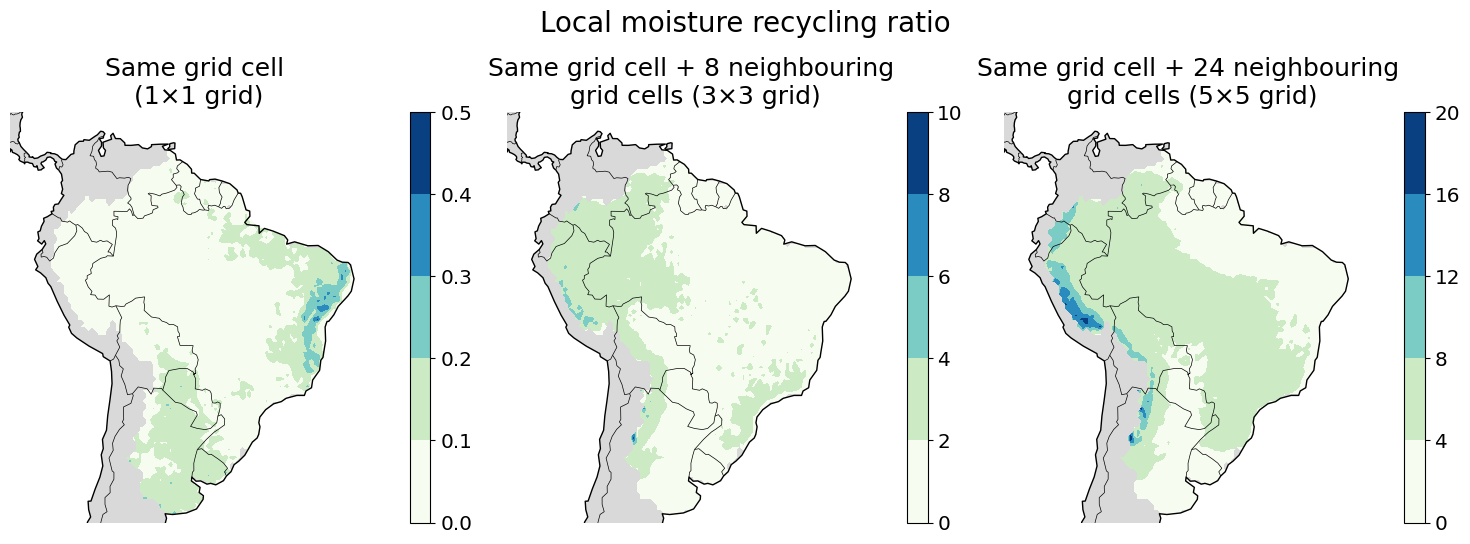

In [22]:
import cartopy as cart

fig = plt.figure(figsize=(15, 5.5))
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]
fig.suptitle('Local moisture recycling ratio', fontsize = '20')

im = (100*b/(Evap_agg.sum(axis = 0)))[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).where(data[::-1].values>0).plot.contourf(cmap = 'GnBu', ax = ax[0],levels = 6, vmax = 0.5, add_colorbar=False)
cb = plt.colorbar(im, pad=0.05, ax = ax[0])
cb.ax.tick_params(labelsize='x-large')

im = (100*b_1/(Evap_agg.sum(axis = 0)))[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).where(data[::-1].values>0).plot.contourf(cmap = 'GnBu', ax = ax[1],levels = 6, add_colorbar=False)
cb = plt.colorbar(im, pad=0.05, ax = ax[1])
cb.ax.tick_params(labelsize='x-large')

im = (100*b_2/(Evap_agg.sum(axis = 0)))[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).where(data[::-1].values>0).plot.contourf(cmap = 'GnBu', ax = ax[2],levels = 6, add_colorbar=False)
cb = plt.colorbar(im, pad=0.05, ax = ax[2])
cb.ax.tick_params(labelsize='x-large')

ax[0].set_title('Same grid cell \n(1×1 grid)', fontsize = '18')
ax[1].set_title('Same grid cell + 8 neighbouring \ngrid cells (3×3 grid)', fontsize = '18')
ax[2].set_title('Same grid cell + 24 neighbouring \ngrid cells (5×5 grid)', fontsize = '18')

for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
plt.tight_layout()

/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/cfs/klemming/projects/supr/chandra/.venv/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


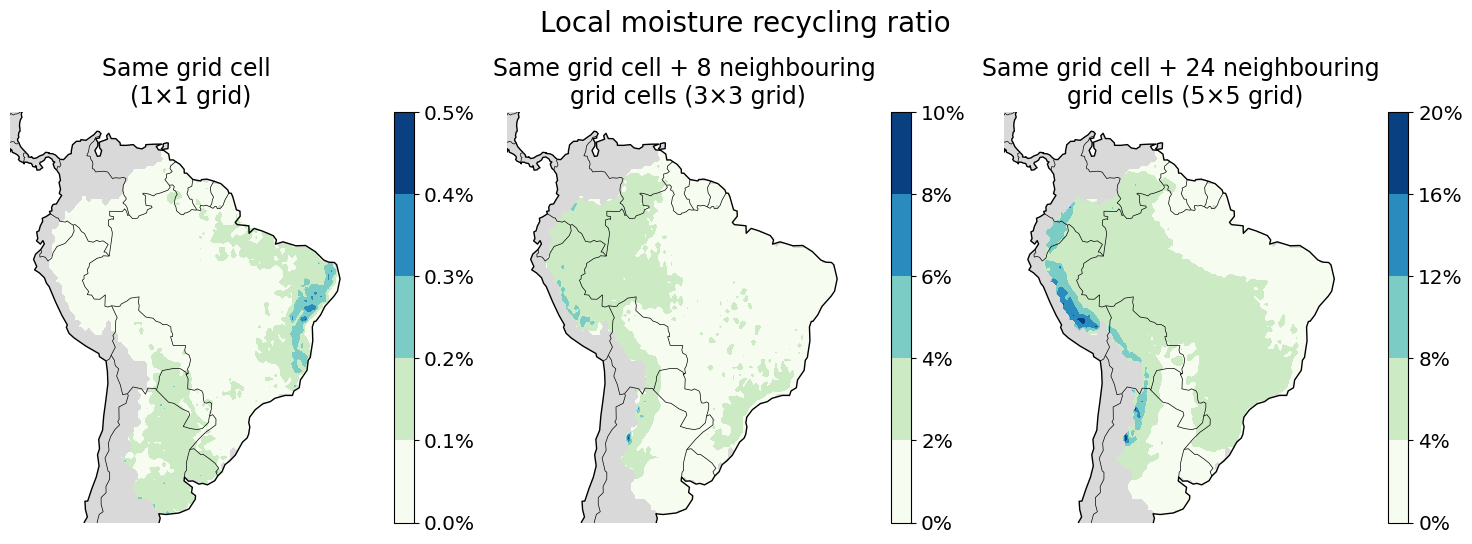

In [26]:
import cartopy as cart
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker  # Imported for percentage formatting

fig = plt.figure(figsize=(15, 5.5))
ax = [
    plt.subplot(131, projection=ccrs.PlateCarree(), aspect="auto"),
    plt.subplot(132, projection=ccrs.PlateCarree(), aspect="auto"),
    plt.subplot(133, projection=ccrs.PlateCarree(), aspect="auto"),
]
fig.suptitle("Local moisture recycling ratio", fontsize="20")

# First subplot
im = (
    (100 * b / (Evap_agg.sum(axis=0)))[::-1,]
    .sel(lat=slice(-39.25, 10.25), lon=slice(280 + 1, 330 + 1))
    .where(data[::-1].values > 0)
    .plot.contourf(cmap="GnBu", ax=ax[0], levels=6, vmax=0.5, add_colorbar=False)
)
cb = plt.colorbar(im, pad=0.05, ax=ax[0])
cb.ax.tick_params(labelsize="x-large")
cb.ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100, decimals=1)
)  # Formats labels with %

# Second subplot
im = (
    (100 * b_1 / (Evap_agg.sum(axis=0)))[::-1,]
    .sel(lat=slice(-39.25, 10.25), lon=slice(280 + 1, 330 + 1))
    .where(data[::-1].values > 0)
    .plot.contourf(cmap="GnBu", ax=ax[1], levels=6, add_colorbar=False)
)
cb = plt.colorbar(im, pad=0.05, ax=ax[1])
cb.ax.tick_params(labelsize="x-large")
cb.ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100, decimals=0)
)  # Formats labels with %

# Third subplot
im = (
    (100 * b_2 / (Evap_agg.sum(axis=0)))[::-1,]
    .sel(lat=slice(-39.25, 10.25), lon=slice(280 + 1, 330 + 1))
    .where(data[::-1].values > 0)
    .plot.contourf(cmap="GnBu", ax=ax[2], levels=6, add_colorbar=False)
)
cb = plt.colorbar(im, pad=0.05, ax=ax[2])
cb.ax.tick_params(labelsize="x-large")
cb.ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100, decimals=0)
)  # Formats labels with %

ax[0].set_title("Same grid cell \n(1×1 grid)", fontsize="17")
ax[1].set_title(
    "Same grid cell + 8 neighbouring \ngrid cells (3×3 grid)", fontsize="17"
)
ax[2].set_title(
    "Same grid cell + 24 neighbouring \ngrid cells (5×5 grid)", fontsize="17"
)

for i in range(3):
    ax[i].coastlines(lw=1)
    ax[i].add_feature(
        cart.feature.BORDERS, linestyle="-", alpha=1, lw=0.5
    )  # Fixed cartopy -> cart typo
    ax[i].set_xlim(-85, -30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis("off")
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor="#d9d9d9")

plt.tight_layout()


In [ ]:
##### Mositure recycling nearby

In [1]:
"""
1. Change the landholder in data.values
2. Change file name

"""
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *

Landuse_map = 'Mapbiomas'

"""
1. Load your evaporation dataset here
"""
print('To run the model, your data format should be:')
print('Latitude = [ 90 → -90 ]')
print('Longitude = [ 0 → 360 ]')
print(' ')

lats=np.arange(90,-90,-0.5)
lons=np.arange(0,360,0.5)

Evap_agg = xr.open_mfdataset('/home/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

print('Your Evaporation data:')
print('Latitude = [', Evap_agg.lat[0].values, '→', Evap_agg.lat[-1].values, ']')
print('Longitude = [', Evap_agg.lon[0].values, '→', Evap_agg.lon[-1].values, ']')


"""
2. Funtion for forwardtracking (monthly) [Annual can be derived using 'np.sum' funtion] 
"""
### Forward tracking
def get_closest_index(lats,lat):
    import operator
    lat_index, min_value = min(enumerate(abs(lats-lat)), key=operator.itemgetter(1))
    return lat_index

    
def MR_footprint_forward_recycling(latitude, longitude, neigbouringpixel = 0):
    i = neigbouringpixel
    global forward_fp, Evap_agg_recycled
    latidx=get_closest_index(lats,latitude)
    lonidx=get_closest_index(lons,longitude)
    
    Evap_agg_recycled = []
    print('calculating '+str(2*int(i)+1)+'x'+str(2*int(i)+1))
    for month in range(1,13):
        MR = xr.open_dataset('/home/chandra/data/Paper4_Self-influencing_feedback/utrack_climatology/utrack_climatology_0.5_'+
                                                                 str(month).zfill(2)+'.nc').moisture_flow
        fp = MR[get_closest_index(lats,latitude), get_closest_index(lons,longitude), :, :].values
        fp=fp*-0.1
        fp=np.e**fp
        fp[fp==1]=0
        forward_fp=fp/np.nansum(fp)
        forward_fp= forward_fp[get_closest_index(lats,latitude)-int(i):get_closest_index(lats,latitude)+int(i)+1, get_closest_index(lons,longitude)-int(i):get_closest_index(lons,longitude)+int(i)+1]
        forward_fp = forward_fp*((Evap_agg[month-1])[get_closest_index(lats,latitude), get_closest_index(lons,longitude)].values)
        Evap_agg_recycled.append(forward_fp)
    Evap_agg_recycled = np.nansum(Evap_agg_recycled, axis = 0)
    #print(Evap_agg_recycled)
    return Evap_agg_recycled

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


To run the model, your data format should be:
Latitude = [ 90 → -90 ]
Longitude = [ 0 → 360 ]
 
Your Evaporation data:
Latitude = [ 89.75 → -89.75 ]
Longitude = [ 0.0 → 359.5 ]


/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/plugins.py:64: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [2]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360

Lat = []
for lat in np.argwhere(data.values == 1).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 1).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

Evap_footprint = np.zeros(shape=(360,720))
Evap_footprint[:] = np.nan

var_start = 0
#neigbouringpixel = input("Neigbouring pixel: ")
#var_stop = Screened_data.shape[0]
var_stop = 1

def forward_tracking_local(j):
    print("You entered: " + str(var_start), str(var_stop))
    print(j)
    for i in tqdm(range(var_start,var_stop)):
        latitude, longitude = (Screened_data.iloc[i]).values
        Original_array = Evap_footprint[get_closest_index(lats,latitude)-j:get_closest_index(lats,latitude)+j+1, get_closest_index(lons,longitude)-j:get_closest_index(lons,longitude)+j+1]
        Evap_footprint[get_closest_index(lats,latitude)-j:get_closest_index(lats,latitude)+j+1, 
                           get_closest_index(lons,longitude)-j:get_closest_index(lons,longitude)+j+1] = np.nansum([Original_array, MR_footprint_forward_recycling(latitude, longitude, j)], axis = 0)

    Evap_footprint_monthly_sum = xr.DataArray(Evap_footprint, coords=[Evap_agg.lat.values, Evap_agg.lon.values],
                                              dims=['lat', 'lon'], name = 'Evap_footprint', 
                                              attrs=dict(description="Evaporation Footprint", units="mm/month"))
    Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholder_'+str(2*j+1)+'x'+str(2*j+1)+'_.nc')

In [3]:
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = [4,9,13,18] #Running it in a group of 100, 10 times
    pool.map(forward_tracking_local, grid)
    pool.close()
    pool.join()

You entered: 0You entered: 0You entered: 0You entered: 0    1111



918413





  0%|          | 0/1 [00:00<?, ?it/s]

calculating 37x37
calculating 19x19calculating 9x9calculating 27x27




100%|██████████| 1/1 [00:54<00:00, 54.38s/it]


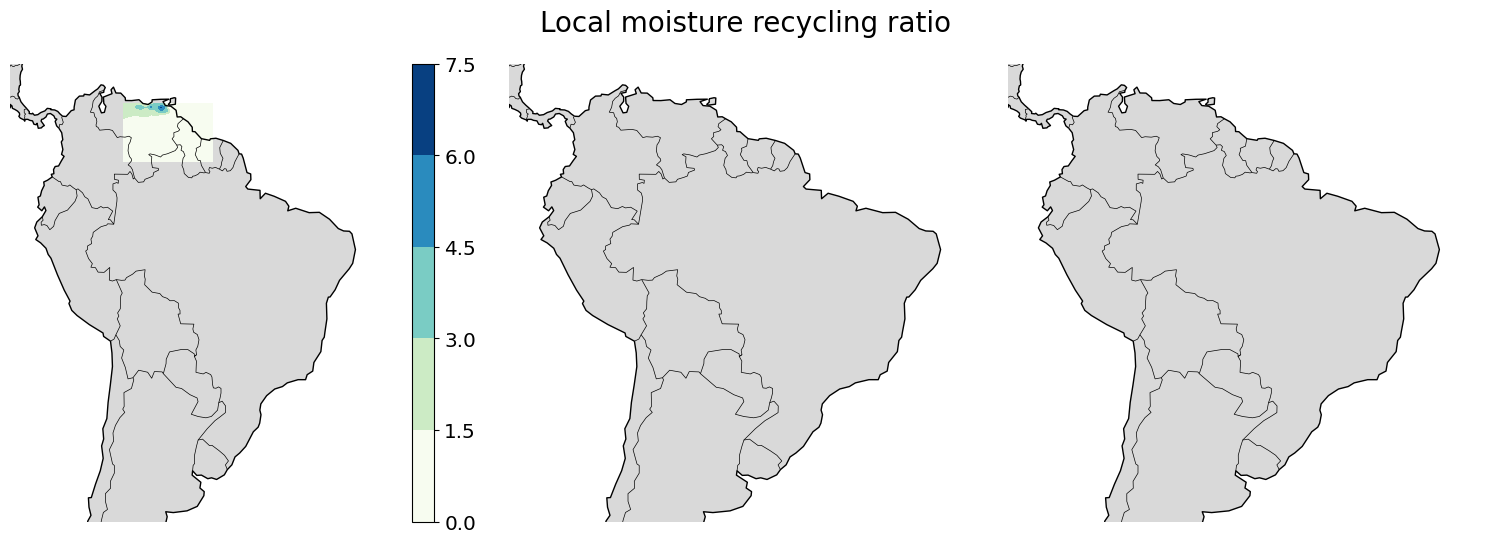

In [87]:
import cartopy as cart

fig = plt.figure(figsize=(15, 5.5))
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]
fig.suptitle('Local moisture recycling ratio', fontsize = '20')

#im = Evap_footprint_monthly_sum[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).where(data[::-1].values>0).plot.contourf(cmap = 'GnBu', ax = ax[0],levels = 6, add_colorbar=False)
im = Evap_footprint_monthly_sum[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).plot.contourf(cmap = 'GnBu', ax = ax[0],levels = 6, add_colorbar=False)
cb = plt.colorbar(im, pad=0.05, ax = ax[0])
cb.ax.tick_params(labelsize='x-large')

for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
plt.tight_layout()

In [66]:
Screened_data

,Lat,Lon
0,9.75,298.25
1,9.25,297.75
2,9.25,298.25
3,9.25,298.75
4,8.75,298.25
...,...,...
1293,-35.25,301.25
1294,-35.25,301.75
1295,-37.75,302.25
1296,-38.75,297.75


In [45]:
55.55*19

1055.45

In [51]:
2000/55

36.36363636363637

In [ ]:
### Backtracking the moisture flow

In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *

"""
1. Load your evaporation dataset here
"""
print('To run the model, your data format should be:')
print('Latitude = [ 90 → -90 ]')
print('Longitude = [ 0 → 360 ]')
print(' ')

lats=np.arange(90,-90,-0.5)
lons=np.arange(0,360,0.5)

Evap_agg = xr.open_mfdataset('/home/chandra/data/Kruger/era5/evap_ERA5_monthly_averaged_reanalysis_resampled_monthly_mm_per_month_0.5degree.nc').e[:,::-1].sel(time = slice('2008','2017'))
# Convert to multi-year mean
Evap_agg = Evap_agg.groupby('time.month').mean(dim = 'time')
Evap_agg = (Evap_agg.where(Evap_agg > 0))

print('Your Evaporation data:')
print('Latitude = [', Evap_agg.lat[0].values, '→', Evap_agg.lat[-1].values, ']')
print('Longitude = [', Evap_agg.lon[0].values, '→', Evap_agg.lon[-1].values, ']')


"""
2. Funtion for forwardtracking (monthly) [Annual can be derived using 'np.sum' funtion] 
"""
### Forward tracking
def get_closest_index(lats,lat):
    import operator
    lat_index, min_value = min(enumerate(abs(lats-lat)), key=operator.itemgetter(1))
    return lat_index

    
def MR_footprint_backward(month, latitude, longitude):
    latidx=get_closest_index(lats,latitude)
    lonidx=get_closest_index(lons,longitude)
    
    MR = xr.open_dataset('/home/chandra/data/Paper4_Self-influencing_feedback/utrack_climatology/utrack_climatology_0.5_'+
                                                         str(month).zfill(2)+'.nc').moisture_flow
    fp = MR[:,:,get_closest_index(lats,latitude), get_closest_index(lons,longitude)].values
    fp=fp*-0.1
    fp=np.e**fp
    fp[fp==1]=0
    ET = (Evap_agg[month-1]).values
    fp=ET*fp
    backward_fp=fp/np.nansum(fp)
    print(np.nansum(backward_fp).round(2))
    backward_fp = backward_fp*ET
    return backward_fp

def absolute_backward_tracking(j):
    Evap_footprint_monthly = np.zeros(shape=(12,360,720))
    Evap_footprint_monthly_final  = np.zeros(shape=(12,360,720))
    #for j in tqdm(range(Screened_data.shape[0])):
    latitude, longitude = np.array(Screened_data.loc[j])
    print(latitude,longitude)
    #print(latitude, longitude, '\n')
    for i in tqdm(range(12)):
        Evap_footprint_monthly[i,:,:] = MR_footprint_backward(i+1,latitude,longitude)
    Evap_footprint_monthly_final = Evap_footprint_monthly_final + Evap_footprint_monthly

    #Evap_footprint_monthly_sum = xr.DataArray(Evap_footprint_monthly_final, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
    #             dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
    return Evap_footprint_monthly_final


/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


To run the model, your data format should be:
Latitude = [ 90 → -90 ]
Longitude = [ 0 → 360 ]
 
Your Evaporation data:
Latitude = [ 89.75 → -89.75 ]
Longitude = [ 0.0 → 359.5 ]


/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/plugins.py:64: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [4]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360
data

<xarray.DataArray 'Dominance' (y: 100, x: 101)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
  * y        (y) float64 10.25 9.75 9.25 8.75 ... -37.75 -38.25 -38.75 -39.25
  * x        (x) float64 280.8 281.2 281.8 282.2 ... 329.2 329.8 330.2 330.8
Attributes:
    name:          Dominance
    long_name:     Dominance
    grid_mapping:  spatial_ref

In [17]:
Lat = []
for lat in np.argwhere(data.values == 1).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 1).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Smallholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [04:04<00:00, 20.35s/it]

100%|██████████| 12/12 [02:59<00:00, 14.97s/it]

100%|██████████| 12/12 [02:58<00:00, 14.88s/it]

100%|██████████| 12/12 [04:11<00:00, 20.97s/it]

100%|██████████| 12/12 [03:47<00:00, 18.96s/it]

100%|██████████| 12/12 [03:03<00:00, 15.30s/it]

100%|██████████| 12/12 [02:27<00:00, 12.32s/it]

100%|██████████| 12/12 [00:55<00:00,  4.66s/it]


In [7]:
Lat = []
for lat in np.argwhere(data.values == 2).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 2).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Mediumholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [03:45<00:00, 18.78s/it]

100%|██████████| 12/12 [03:45<00:00, 18.80s/it]

100%|██████████| 12/12 [03:45<00:00, 18.80s/it]


100%|██████████| 12/12 [03:45<00:00, 16.83s/it]

100%|██████████| 12/12 [03:45<00:00, 18.80s/it]

  0%|          | 0/12 [00:00<?, ?it/s]8.80s/it]

100%|██████████| 12/12 [03:45<00:00, 18.82s/it]

  0%|          | 0/12 [00:00<?, ?it/s]2.21s/it]

100%|██████████| 12/12 [02:29<00:00, 12.47s/it]

100%|██████████| 12/12 [02:02<00:00, 10.19s/it]

100%|██████████| 12/12 [01:57<00:00,  9.78s/it]

100%|██████████| 12/12 [00:56<00:00,  4.74s/it]


In [ ]:
Lat = []
for lat in np.argwhere(data.values == 3).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 3).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Largeholders_'+Landuse_map+'.nc')


100%|██████████| 12/12 [02:02<00:00, 10.20s/it]

100%|██████████| 12/12 [02:03<00:00, 10.32s/it]

100%|██████████| 12/12 [02:04<00:00, 10.41s/it]

100%|██████████| 12/12 [02:05<00:00, 10.49s/it]

100%|██████████| 12/12 [01:59<00:00,  9.98s/it]

100%|██████████| 12/12 [02:01<00:00, 10.17s/it]

100%|██████████| 12/12 [01:57<00:00,  9.83s/it]

100%|██████████| 12/12 [01:56<00:00,  9.71s/it]

100%|██████████| 12/12 [02:00<00:00, 10.02s/it]

100%|██████████| 12/12 [02:00<00:00, 10.03s/it]

100%|██████████| 12/12 [02:02<00:00, 10.17s/it]

100%|██████████| 12/12 [02:00<00:00, 10.00s/it]

100%|██████████| 12/12 [02:02<00:00, 10.24s/it]

100%|██████████| 12/12 [02:00<00:00, 10.02s/it]

100%|██████████| 12/12 [01:59<00:00,  9.95s/it]

100%|██████████| 12/12 [02:00<00:00, 10.01s/it]

100%|██████████| 12/12 [02:00<00:00, 10.00s/it]

100%|██████████| 12/12 [01:59<00:00,  9.95s/it]

100%|██████████| 12/12 [02:02<00:00, 10.18s/it]

100%|██████████| 12/12 [02:01<00:00, 10.10s/it]

100%|██████████| 12/

In [ ]:
Lat = []
for lat in np.argwhere(data.values == 3).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data.values == 3).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

for i in tqdm(range(Screened_data.shape[0])):
    if i == 0:
        a = absolute_backward_tracking(i)
    else:
        b = absolute_backward_tracking(i)
        a = np.nansum([a,b], axis = 0)
        #np.save('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_All_stakeholders_'+Landuse_map+'.nc', a)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Largeholders_'+Landuse_map+'.nc')


 83%|████████▎ | 10/12 [01:26<00:17,  8.77s/it]

In [ ]:
"""
3. Defining the data for forward tracking
"""
data = xr.open_dataset('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc').Dominance

data['x'] = data.x.values%360
data = data[:,:-1]
#data

LU_Mapbiomas_forest = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif')[0,::-1]
LU_Mapbiomas_forest['x'] = LU_Mapbiomas_forest.x.values%360
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sortby('x')
#LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sel(y = slice(-39.25, 10.25), x = slice(280, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.where(LU_Mapbiomas_forest != 0)
LU_Mapbiomas_forest = LU_Mapbiomas_forest[::-1,]


In [ ]:
data_f = data.where((data == 1) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f

Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [21]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Smallholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:51<00:00, 14.26s/it]

100%|██████████| 12/12 [01:54<00:00,  9.52s/it]

100%|██████████| 12/12 [01:51<00:00,  9.26s/it]

100%|██████████| 12/12 [01:54<00:00,  9.54s/it]

100%|██████████| 12/12 [02:24<00:00, 12.07s/it]

100%|██████████| 12/12 [01:56<00:00,  9.71s/it]

100%|██████████| 12/12 [01:17<00:00,  6.48s/it]


In [26]:
data_f = data.where((data == 2) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f
Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [27]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Mediumholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:03<00:00, 10.25s/it]

100%|██████████| 12/12 [02:03<00:00, 10.30s/it]

100%|██████████| 12/12 [00:59<00:00,  4.95s/it]


In [28]:
data_f = data.where((data == 3) & (LU_Mapbiomas_forest.values == 1))
data_f = data_f/data_f
Lat = []
for lat in np.argwhere(data_f.values == 1).transpose()[0]:
        Lat.append(data_f.y.values[lat])
Lon = []
for lat in np.argwhere(data_f.values == 1).transpose()[1]:
        Lon.append(data_f.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat),
                              'Lon': np.array(Lon)})

In [29]:
"""
4. Running the backtracking code for the screened dataframe 
"""
#Multiprocessing starts here
from multiprocessing import Pool
if __name__ == '__main__':
    pool = Pool()
    grid = np.arange(0,Screened_data.shape[0],1) #Running it in a group of 100, 10 times
    a = pool.map(absolute_backward_tracking, grid)
    #a = np.nansum(a, axis = 0)
    pool.close()
    pool.join()
a = np.nansum(a, axis = 0)

Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Largeholders_'+Landuse_map+'_Forest_only.nc')

100%|██████████| 12/12 [02:01<00:00, 10.14s/it]

100%|██████████| 12/12 [01:56<00:00,  9.74s/it]

100%|██████████| 12/12 [01:38<00:00,  8.17s/it]

100%|██████████| 12/12 [02:03<00:00, 10.27s/it]

100%|██████████| 12/12 [02:02<00:00, 10.21s/it]

100%|██████████| 12/12 [02:00<00:00, 10.04s/it]

100%|██████████| 12/12 [01:57<00:00,  9.76s/it]

100%|██████████| 12/12 [02:01<00:00, 10.13s/it]

100%|██████████| 12/12 [01:43<00:00,  8.64s/it]

100%|██████████| 12/12 [01:21<00:00,  6.81s/it]


In [3]:
### Simon's run
Screened_data = pd.DataFrame({'Lat': [32], 'Lon': [39]})

In [4]:
a = absolute_backward_tracking(0)

32 39


  8%|███████                                                                             | 1/12 [00:04<00:48,  4.39s/it]

1.0


 17%|██████████████                                                                      | 2/12 [00:08<00:44,  4.45s/it]

1.0


 25%|█████████████████████                                                               | 3/12 [00:13<00:40,  4.46s/it]

... (15 outputs left out)

 92%|████████████████████████████████████████████████████████████████████████████       | 11/12 [00:47<00:04,  4.28s/it]

1.0


100%|███████████████████████████████████████████████████████████████████████████████████| 12/12 [00:52<00:00,  4.36s/it]

1.0


In [5]:
Evap_footprint_monthly_sum = xr.DataArray(a, coords=[Evap_agg.month.values, Evap_agg.lat.values, Evap_agg.lon.values],
                 dims=['month', 'lat', 'lon'], name = 'Evap_footprint', attrs=dict(description="Evaporation Footprint", units="mm/month"))

In [13]:
Evap_footprint_monthly_sum.to_netcdf('/home/chandra/data/Backtracking_Simons_run.nc')

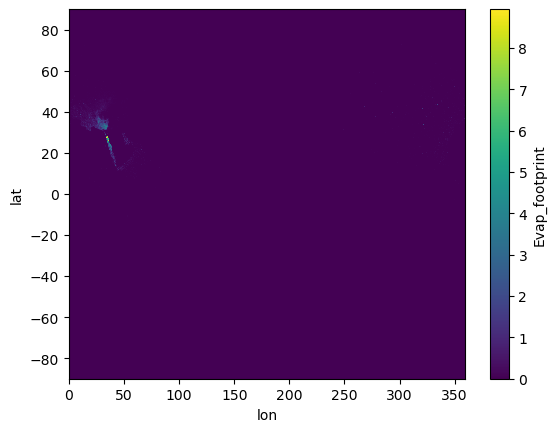

In [6]:
Evap_footprint_monthly_sum.sum(axis = 0).plot()

NameError: name 'cb' is not defined

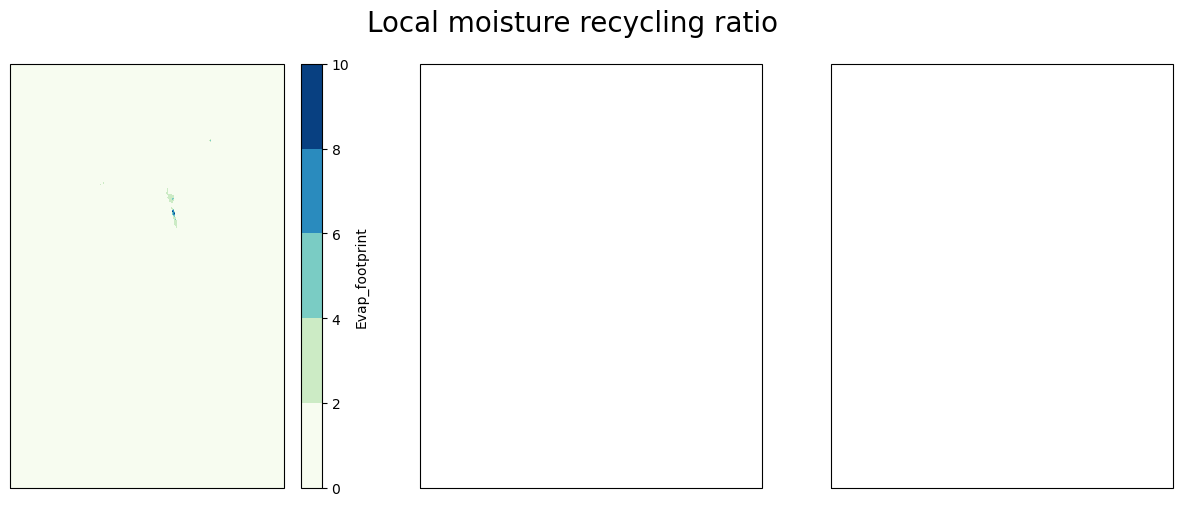

In [7]:
import cartopy as cart

fig = plt.figure(figsize=(15, 5.5))
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]
fig.suptitle('Local moisture recycling ratio', fontsize = '20')

#im = Evap_footprint_monthly_sum[::-1,].sel(lat = slice(-39.25, 10.25), lon = slice(280+1, 330+1)).where(data[::-1].values>0).plot.contourf(cmap = 'GnBu', ax = ax[0],levels = 6, add_colorbar=False)
Evap_footprint_monthly_sum.sum(axis = 0).plot.contourf(cmap = 'GnBu', ax = ax[0],levels = 6, add_colorbar=True)
#cb = plt.colorbar(im, pad=0.05, ax = ax[0])
cb.ax.tick_params(labelsize='x-large')

for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(20, 50)
    ax[i].set_ylim(10, -15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
plt.tight_layout()

In [19]:
Evap_agg.sel(lat = '32', lon = '39', method='nearest').sum().values

array(112.45889366)

In [11]:
Evap_footprint_monthly_sum.sum()

<xarray.DataArray 'Evap_footprint' ()>
array(1273.43621984)

In [13]:
P_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_precipitation/ERA5_daily/era5_precipitation_daily_daysum_*_p25.nc').tp[:,::-1].sel(time = slice('2008','2017'), latitude = slice(31, 33), longitude = slice(38,40))
P_era5 = P_era5[:,:-1,:-1]*(1000)
P_era5 = P_era5.resample(time = '1Y').sum('time')
P_era5 = P_era5.mean(axis = 0)
P_era5 = P_era5.coarsen(latitude = 2, longitude = 2).mean()

In [20]:
P_era5.sel(latitude = '32', longitude = '39', method='nearest').sum().values

array(84.08639857)

In [22]:
P_era5.values

array([[58.72158393, 65.93843459, 66.95222996, 65.83422856],
       [64.32623918, 71.59375137, 73.20674517, 71.94176386],
       [65.64697161, 81.6364095 , 84.08639857, 84.79335722],
       [73.14278255, 83.52885863, 86.79205248, 87.55427753]])